## Project #3: Sentiment Analysis of Reviews

**Name: Evan Sertic**

**Date: 11/25/2026**

Introduction Question:
What is the overall public opinion of the Samsung Galaxy S25? Do the comments reflect a more positive or negative opinion?

In [33]:
import requests
import pandas as pd
import json
import os
import re
import html
from textblob import TextBlob
from textblob.sentiments import NaiveBayesAnalyzer
import nltk
import matplotlib.pyplot as plt

In [4]:
from getpass import getpass

API_KEY = getpass("Enter your YouTube API key: ")

Enter your YouTube API key:  ········


In [6]:
#testing the connection
video_id = "1HFLee3XkcE"

url = "https://www.googleapis.com/youtube/v3/commentThreads"

params = {
    "part": "snippet",
    "videoId": video_id,
    "maxResults": 1,
    "textFormat": "plainText",
    "key": API_KEY
}

response = requests.get(url, params=params)

data = response.json()

if response.status_code == 200:
    print("API connection successful!")
    print("Sample comment:")
    print(data["items"][0]["snippet"]["topLevelComment"]["snippet"]["textDisplay"])
else:
    print("API connection failed.")
    print(data)

API connection successful!
Sample comment:
Our One UI 7 video is up in a mobile aspect for your phone: https://www.youtube.com/watch?v=CG3qH-sLmyk


In [7]:
comments = []

next_page_token = None

while len(comments) < 300:

    params = {
        "part": "snippet",
        "videoId": video_id,
        "maxResults": 100,
        "textFormat": "plainText",
        "key": API_KEY
    }

    if next_page_token:
        params["pageToken"] = next_page_token

    response = requests.get(url, params=params)
    data = response.json()

    if response.status_code != 200:
        print("Error retrieving comments:", data)
        break

    for item in data.get("items", []):
        comment = item["snippet"]["topLevelComment"]["snippet"]

        comments.append({
            "author": comment["authorDisplayName"],
            "comment": comment["textDisplay"],
            "published_at": comment["publishedAt"],
            "like_count": comment["likeCount"]
        })

    next_page_token = data.get("nextPageToken")

    if not next_page_token:
        break

print("Total comments collected:", len(comments))

Total comments collected: 300


In [8]:
df = pd.DataFrame(comments)

df.head()

,author,comment,published_at,like_count
0,@GSMArenaOfficial,Our One UI 7 video is up in a mobile aspect fo...,2025-03-07T22:31:03Z,28
1,@LuckyParachutePod,"Tbh the best phone ive ever had , just for the...",2026-11-17T15:05:54Z,0
2,@MsGats123,I don't like the battery life ever since they ...,2026-11-14T14:05:22Z,0
3,@whatdoyoucare777,Who's we? There's just one of you? How many de...,2026-11-09T14:21:33Z,0
4,@loveelle3357,who is this guy?,2026-11-02T10:06:50Z,0


In [9]:
df.shape

(300, 4)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   author        300 non-null    str  
 1   comment       300 non-null    str  
 2   published_at  300 non-null    str  
 3   like_count    300 non-null    int64
dtypes: int64(1), str(3)
memory usage: 53.2 KB


In [11]:
df["comment"].sample(10)

190    I've had my S23 since it came out. Haven't fel...
86                                                    Ew
299         switching from my s10e using since twenty 19
14     Watching from my Galaxy S25. A beast. I'm so h...
64                                           Cute babe 😢
106    I just got a new phone I had the S9 since the ...
150    what does he say at 1:10? ("as ever, you get I...
63     For future reference.. You showing us the soun...
126    I wish they had put in a bigger battery like a...
130    Your video was OK but what we need is the comp...
Name: comment, dtype: str

In [13]:
#checking for missing values
df.isnull().sum()

author          0
comment         0
published_at    0
like_count      0
dtype: int64

In [14]:
#checking for duplicate comments
df["comment"].duplicated().sum()

np.int64(10)

In [15]:
#the new cleaned data frame
cleaned_df = df.copy()

#removing rows with missing comments
cleaned_df = cleaned_df.dropna(subset=["comment"])

#removing duplicate comments
cleaned_df = cleaned_df.drop_duplicates(subset=["comment"])

#removing empty comments
cleaned_df = cleaned_df[
    cleaned_df["comment"].str.strip() != ""
]

print("Original comments:", len(df))
print("Cleaned comments:", len(cleaned_df))

Original comments: 300
Cleaned comments: 290


In [16]:
#function to clean up the comment text
def clean_text(text):

    #converting HTML into readable characters
    text = html.unescape(text)

    #removing any URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    #removing extra whitespace
    text = re.sub(r"\s+", " ", text)

    #removing extra whitespace before and after comments
    text = text.strip()

    return text

In [18]:
#comparison between cleaned/uncleaned comments
cleaned_df["cleaned_comment"] = cleaned_df["comment"].apply(clean_text)

cleaned_df[["comment", "cleaned_comment"]].head(10)

,comment,cleaned_comment
0,Our One UI 7 video is up in a mobile aspect fo...,Our One UI 7 video is up in a mobile aspect fo...
1,"Tbh the best phone ive ever had , just for the...","Tbh the best phone ive ever had , just for the..."
2,I don't like the battery life ever since they ...,I don't like the battery life ever since they ...
3,Who's we? There's just one of you? How many de...,Who's we? There's just one of you? How many de...
4,who is this guy?,who is this guy?
5,I tried the S25 out and i feel like it's a sma...,I tried the S25 out and i feel like it's a sma...
6,5g s25,5g s25
7,Should i buy the galaxy fold 6 or the base sam...,Should i buy the galaxy fold 6 or the base sam...
8,My S10 was fantastic for it's time but a salt ...,My S10 was fantastic for it's time but a salt ...
9,"I bought a Samsung S25 three months ago, but I...","I bought a Samsung S25 three months ago, but I..."


In [19]:
cleaned_df.shape

(290, 5)

In [20]:
cleaned_df["cleaned_comment"].sample(10)

13     WTF?? you can't even turn the phone up to max ...
39              The Samsung fingerprint scanner is trash
259             S22 is exactly the same with the update.
163    Just switched to one from a Motorola edge+ 202...
198    Is the Snapdragon processor inside all phones ...
285    It sounds thin without bass. Compared it with ...
109                             What is a bright shadow?
241                        why did they ignore 8K video?
280    And looks like you guys got a Defective Unit y...
128    We don't have the 512 gb in America, does anyo...
Name: cleaned_comment, dtype: str

In [ ]:
%pip install textblob nltk wordcloud

In [24]:
def get_sentiment(text):

    analysis = TextBlob(text)

    return analysis.sentiment.polarity

cleaned_df["textblob_polarity"] = cleaned_df["cleaned_comment"].apply(get_sentiment)

cleaned_df[["cleaned_comment", "textblob_polarity"]].head(10)

,cleaned_comment,textblob_polarity
0,Our One UI 7 video is up in a mobile aspect fo...,0.000000
1,"Tbh the best phone ive ever had , just for the...",0.305556
2,I don't like the battery life ever since they ...,0.057273
3,Who's we? There's just one of you? How many de...,0.500000
4,who is this guy?,0.000000
5,I tried the S25 out and i feel like it's a sma...,-0.212500
6,5g s25,0.000000
7,Should i buy the galaxy fold 6 or the base sam...,-0.800000
8,My S10 was fantastic for it's time but a salt ...,-0.025000
9,"I bought a Samsung S25 three months ago, but I...",-0.134375


In [27]:
def classify_sentiment(score):

    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    else:
        return "Neutral"

cleaned_df["textblob_sentiment"] = cleaned_df["textblob_polarity"].apply(classify_sentiment)

cleaned_df["textblob_sentiment"].value_counts()

textblob_sentiment
Positive    129
Neutral     112
Negative     49
Name: count, dtype: int64

In [29]:
# Initialize the Naive Bayes analyzer once
nb_analyzer = NaiveBayesAnalyzer()

print("Naive Bayes analyzer initialized successfully.")

Naive Bayes analyzer initialized successfully.


In [30]:
def naive_bayes_sentiment(text):

    analysis = TextBlob(text, analyzer=nb_analyzer)

    return analysis.sentiment.classification


cleaned_df["naive_bayes_sentiment"] = cleaned_df["cleaned_comment"].apply(naive_bayes_sentiment)

cleaned_df[["cleaned_comment", "naive_bayes_sentiment"]].head(10)

,cleaned_comment,naive_bayes_sentiment
0,Our One UI 7 video is up in a mobile aspect fo...,pos
1,"Tbh the best phone ive ever had , just for the...",pos
2,I don't like the battery life ever since they ...,neg
3,Who's we? There's just one of you? How many de...,neg
4,who is this guy?,neg
5,I tried the S25 out and i feel like it's a sma...,neg
6,5g s25,pos
7,Should i buy the galaxy fold 6 or the base sam...,pos
8,My S10 was fantastic for it's time but a salt ...,neg
9,"I bought a Samsung S25 three months ago, but I...",pos


In [31]:
cleaned_df["naive_bayes_sentiment"].value_counts()

naive_bayes_sentiment
pos    168
neg    122
Name: count, dtype: int64

In [32]:
comparison = pd.crosstab(
    cleaned_df["textblob_sentiment"],
    cleaned_df["naive_bayes_sentiment"]
)

comparison

naive_bayes_sentiment,neg,pos
textblob_sentiment,,
Negative,21,28
Neutral,45,67
Positive,56,73


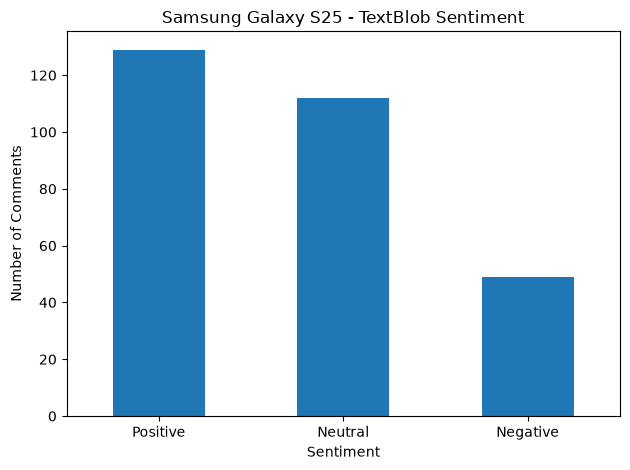

In [34]:
cleaned_df["textblob_sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"]
).plot(
    kind="bar",
    title="Samsung Galaxy S25 - TextBlob Sentiment",
    xlabel="Sentiment",
    ylabel="Number of Comments"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

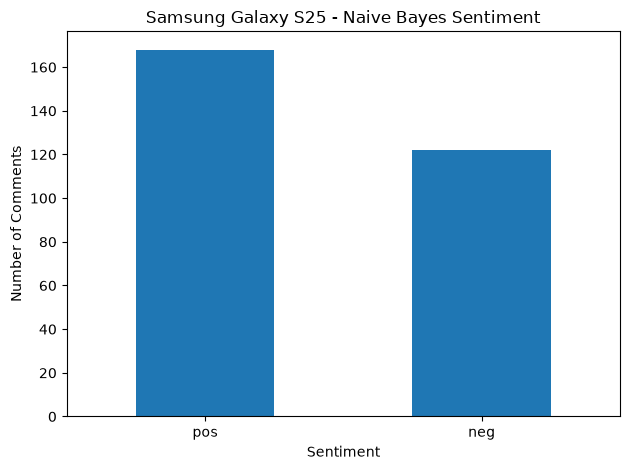

In [35]:
cleaned_df["naive_bayes_sentiment"].value_counts().reindex(
    ["pos", "neg"]
).plot(
    kind="bar",
    title="Samsung Galaxy S25 - Naive Bayes Sentiment",
    xlabel="Sentiment",
    ylabel="Number of Comments"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Conclusion:**

*In summary, the analysis of the YouTube review of the Samsung Galaxy S25 showed that reactions were generally positive. TextBlob's analyzer classfied 44.5% of comments as positive, while 38.6% were neutral, and 16.9% were negative. In comparison, Naive Bayers analyzed 57.9% as positive, and 42.1% as negative.*


*The results showed that different analysis methods can produce noticeably different classifications. TextBlob has a neutral category, whereas Naive Bayes did not, which drastically changed the produced results. Overall, this project did a great job of showing how Python libraries can be used to examine public opinions, identify trends, all while comparing two different approaches to analyzing text.*